# Universidad de los Andes
## Maestría en Inteligencia Artificial — Ingeniería de Datos y Características
### Estudio de Caso: Municipio de Villavicencio, Meta (Código DIVIPOLA: 50001)

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Maia_Final

Mounted at /content/drive
/content/drive/MyDrive/Maia_Final


## 1. Contexto y Parámetros de Ejecución: Villavicencio (2010–2025)

Este notebook replica de forma estandarizada el *pipeline* de exploración, ingeniería de características y modelado desarrollado en el **notebook base de Ibagué (`73001`)**, con el fin de evaluar la capacidad de generalización del sistema de alertas tempranas en el piedemonte llanero (**Villavicencio, Meta — código DIVIPOLA `50001`**). *(La fundamentación teórica detallada de cada método se encuentra documentada en el notebook principal de Ibagué).*

### Parámetros Clave del Experimento
* **Unidad de análisis y periodo:** Municipio-mes para **Villavicencio** (`COD_DPTO_O == 50`, `COD_MUN_O == 1`), ventana **`2010–2025`** (192 meses calendario; **189 meses efectivos** tras rezagos).
* **Datos epidemiológicos (SIVIGILA — Evento 210):** Casos confirmados (laboratorio o nexo epidemiológico) agregados mensualmente según fecha de inicio de síntomas (`INI_SIN`).
* **Datos climáticos (Google Earth Engine):** Reanálisis diario **ECMWF ERA5-Land** (resolución $0,1^\circ \approx 11\text{ km}$) delimitado con polígono municipal **FAO GAUL** (temperatura media, mínima y máxima en $^\circ\text{C}$, precipitación acumulada en $\text{mm}$ y días con lluvia $> 1\text{ mm}$).
* **Ingeniería de variables y objetivo:** Rezagos retrospectivos de 1 a 3 meses ($t-1, t-2, t-3$), media móvil trimestral (`casos_media_movil_3m`) y variable objetivo binaria basada en canal endémico estacional (`exceso_casos = 1` si $\text{Casos}_t > Q_{3,\text{mes}}$).
* **Evaluación y modelado:** Correlación no paramétrica de Spearman ($\rho$), diagnóstico de colinealidad (VIF) y comparación temporal estricta (**Train:** `2010–2018`, **Val:** `2019–2021`, **Test:** `2022–2025`) entre Referencia Estacional, Regresión Logística L2 y XGBoost.

In [2]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

In [3]:
# Rutas con los datos de Villavicencio en Google Drive
RUTA_CARPETA_SIVIGILA = '/content/drive/MyDrive/Maia_Final/Datos-Dengue'
RUTA_CARPETA_CLIMA = '/content/drive/MyDrive/Maia_Final/GEE_Clima_Villavicencio'

# Validamos que las carpetas existan
print("Existe SIVIGILA?:", os.path.exists(RUTA_CARPETA_SIVIGILA))
print("Existe CLIMA?:", os.path.exists(RUTA_CARPETA_CLIMA))

Existe SIVIGILA?: True
Existe CLIMA?: True


In [4]:
COD_DPTO_Villavicencio = 50       # Meta
COD_MUN_Villavicencio = 1         # Villavicencio (DIVIPOLA 50001)
ANIO_INICIO = 2010
ANIO_FIN = 2025

RUTA_ARCHIVOS_SIVIGILA = RUTA_CARPETA_SIVIGILA + '/*'
RUTA_ARCHIVOS_CLIMA = RUTA_CARPETA_CLIMA + '/*.csv'

In [5]:
print("Archivos en GEE_Clima_Villavicencio:")
archivos_clima_reales = sorted(os.listdir(RUTA_CARPETA_CLIMA))
print(archivos_clima_reales)

print("\nArchivos en Datos-Dengue:")
archivos_sivigila_reales = sorted(os.listdir(RUTA_CARPETA_SIVIGILA))
print(archivos_sivigila_reales)

Archivos en GEE_Clima_Villavicencio:
['clima_diario_villavicencio_2010.csv', 'clima_diario_villavicencio_2011.csv', 'clima_diario_villavicencio_2012.csv', 'clima_diario_villavicencio_2013.csv', 'clima_diario_villavicencio_2014.csv', 'clima_diario_villavicencio_2015.csv', 'clima_diario_villavicencio_2016.csv', 'clima_diario_villavicencio_2017.csv', 'clima_diario_villavicencio_2018.csv', 'clima_diario_villavicencio_2019.csv', 'clima_diario_villavicencio_2020.csv', 'clima_diario_villavicencio_2021.csv', 'clima_diario_villavicencio_2022.csv', 'clima_diario_villavicencio_2023.csv', 'clima_diario_villavicencio_2024.csv', 'clima_diario_villavicencio_2025.csv']

Archivos en Datos-Dengue:
['Datos_2007_210.xlsx', 'Datos_2008_210.xlsx', 'Datos_2009_210.xlsx', 'Datos_2010_210.xlsx', 'Datos_2011_210.xlsx', 'Datos_2012_210.xlsx', 'Datos_2013_210.xlsx', 'Datos_2014_210.xlsx', 'Datos_2015_210.xlsx', 'Datos_2016_210.xlsx', 'Datos_2017_210.xlsx', 'Datos_2018_210.xlsx', 'Datos_2019_210.xlsx', 'Datos_2020

In [6]:
def procesar_sivigila_Villavicencio(ruta_archivos_sivigila, solo_confirmados=True):
    """
    Carga todos los archivos anuales de SIVIGILA (Excel/CSV), filtra ocurrencia
    en Villavicencio (DIVIPOLA 50001), audita calidad de fechas y calcula agregación mensual.
    """
    archivos = glob.glob(ruta_archivos_sivigila)
    print(f"--> Archivos SIVIGILA detectados: {len(archivos)}")

    registros_Villavicencio = []
    auditoria_calidad = []

    for archivo in sorted(archivos):
        nombre_arch = os.path.basename(archivo)
        print(f"Procesando: {nombre_arch}...")

        # Lectura según extensión
        if archivo.endswith('.xlsx') or archivo.endswith('.xls'):
            df = pd.read_excel(archivo)
        else:
            df = pd.read_csv(archivo, low_memory=False)

        total_nacional = len(df)

        # Estandarización de códigos DIVIPOLA
        df['COD_DPTO_O'] = pd.to_numeric(df['COD_DPTO_O'], errors='coerce')
        df['COD_MUN_O'] = pd.to_numeric(df['COD_MUN_O'], errors='coerce')

        # Filtro estricto por Ocurrencia en Villavicencio (50001)
        filtro_Villavicencio = (df['COD_DPTO_O'] == COD_DPTO_Villavicencio) & (df['COD_MUN_O'] == COD_MUN_Villavicencio)
        df_vil = df[filtro_Villavicencio].copy()

        if len(df_vil) == 0:
            continue

        # Conversión y auditoría de fechas
        df_vil['INI_SIN_DT'] = pd.to_datetime(df_vil['INI_SIN'], errors='coerce')
        df_vil['FEC_NOT_DT'] = pd.to_datetime(df_vil['FEC_NOT'], errors='coerce')

        # Inconsistencias de calidad
        fechas_nulas = df_vil['INI_SIN_DT'].isna().sum()
        inconsistencias_fec = (df_vil['FEC_NOT_DT'] < df_vil['INI_SIN_DT']).sum()

        # Criterio INS: Selección de casos confirmados vs probables
        if 'confirmados' in df_vil.columns:
            casos_conf = (df_vil['confirmados'] == 1).sum()
        else:
            casos_conf = df_vil['TIP_CAS'].isin([2, 3, '2', '3']).sum()

        auditoria_calidad.append({
            'archivo': nombre_arch,
            'total_nacional': total_nacional,
            'total_Villavicencio': len(df_vil),
            'confirmados_Villavicencio': casos_conf,
            'tasa_confirmacion_%': round((casos_conf / len(df_vil)) * 100, 2),
            'fechas_invalidas': fechas_nulas,
            'inconsistencia_fec_not_menor': inconsistencias_fec
        })

        # Filtrado de casos válidos
        if solo_confirmados:
            if 'confirmados' in df_vil.columns:
                df_vil = df_vil[df_vil['confirmados'] == 1]
            else:
                df_vil = df_vil[df_vil['TIP_CAS'].isin([2, 3, '2', '3'])]

        # Excluir fechas no válidas
        df_vil = df_vil.dropna(subset=['INI_SIN_DT'])
        registros_Villavicencio.append(df_vil[['INI_SIN_DT', 'FEC_NOT_DT', 'ANO', 'SEMANA']])

    df_consolidado = pd.concat(registros_Villavicencio, ignore_index=True)
    df_auditoria = pd.DataFrame(auditoria_calidad)

    # Asignar año-mes según fecha real de inicio de síntomas
    df_consolidado['periodo'] = df_consolidado['INI_SIN_DT'].dt.to_period('M')

    # Agregación mensual de casos
    serie_mensual = df_consolidado.groupby('periodo').size().reset_index(name='casos_dengue')
    serie_mensual['fecha'] = serie_mensual['periodo'].dt.to_timestamp()

    return serie_mensual, df_auditoria

In [7]:
def procesar_clima_Villavicencio(ruta_archivos_clima):
    """
    Carga series climáticas diarias de Villavicencio (ERA5-Land) y las agrega a nivel mensual.
    """
    archivos = sorted(glob.glob(ruta_archivos_clima))
    print(f"--> Archivos Climáticos detectados: {len(archivos)}")

    if len(archivos) == 0:
        raise FileNotFoundError(
            f"No se encontraron archivos en el patrón: '{ruta_archivos_clima}'. "
            "Revisa la extensión (.csv vs .CSV vs .xlsx) o que la carpeta no esté vacía."
        )

    lista_dfs = []
    for f in archivos:
        print(f"Leyendo clima: {os.path.basename(f)}...")
        if f.lower().endswith('.csv'):
            lista_dfs.append(pd.read_csv(f))
        elif f.lower().endswith(('.xlsx', '.xls')):
            lista_dfs.append(pd.read_excel(f))

    df_clima = pd.concat(lista_dfs, ignore_index=True)
    df_clima['fecha'] = pd.to_datetime(df_clima['fecha'], errors='coerce')
    df_clima = df_clima.dropna(subset=['fecha']).sort_values('fecha')

    df_clima['periodo'] = df_clima['fecha'].dt.to_period('M')

    # Agregación mensual metodológica
    clima_mensual = df_clima.groupby('periodo').agg(
        temp_media=('temp_media_c', 'mean'),
        temp_min_media=('temp_min_c', 'mean'),
        temp_max_media=('temp_max_c', 'mean'),
        precipitacion_total=('precipitacion_mm', 'sum'),
        precipitacion_max_dia=('precipitacion_mm', 'max'),
        dias_con_lluvia=('precipitacion_mm', lambda x: (x > 1.0).sum())
    ).reset_index()

    clima_mensual['fecha'] = clima_mensual['periodo'].dt.to_timestamp()
    return clima_mensual

In [8]:
def construir_dataset_modelado(serie_casos, serie_clima, anio_ini=2010, anio_fin=2025):
    """
    Construye calendario continuo de 192 meses (2010-2025), une fuentes, calcula canales
    endémicos (umbral de exceso Q3) y genera variables rezagadas (189 meses efectivos).
    """
    # 1. Calendario mensual completo para evitar saltos temporales
    rango_completo = pd.date_range(start=f'{anio_ini}-01-01', end=f'{anio_fin}-12-01', freq='MS')
    df_base = pd.DataFrame({'fecha': rango_completo})
    df_base['periodo'] = df_base['fecha'].dt.to_period('M')

    # Cruce con casos (los meses sin casos se imputan en 0)
    df_merge = pd.merge(df_base, serie_casos[['periodo', 'casos_dengue']], on='periodo', how='left')
    df_merge['casos_dengue'] = df_merge['casos_dengue'].fillna(0)

    # Cruce con clima
    df_merge = pd.merge(df_merge, serie_clima.drop(columns=['fecha']), on='periodo', how='left')

    # Mes del año para modelar estacionalidad
    df_merge['mes'] = df_merge['fecha'].dt.month

    # 2. Definición del umbral histórico de exceso (Canal endémico mensual: Percentil 75)
    umbral_estacional = df_merge.groupby('mes')['casos_dengue'].transform(lambda x: x.quantile(0.75))
    df_merge['umbral_q3'] = umbral_estacional
    df_merge['exceso_casos'] = (df_merge['casos_dengue'] > df_merge['umbral_q3']).astype(int)

    # 3. Ingeniería de Rezagos (Lags 1, 2 y 3) para casos y variables climáticas
    features_a_rezagar = ['casos_dengue', 'temp_media', 'temp_min_media', 'precipitacion_total', 'dias_con_lluvia']

    for col in features_a_rezagar:
        for lag in [1, 2, 3]:
            df_merge[f'{col}_lag{lag}'] = df_merge[col].shift(lag)

    # Medias móviles retrospectivas (ventana de 3 meses en retraso)
    df_merge['casos_media_movil_3m'] = df_merge['casos_dengue_lag1'].rolling(window=3).mean()
    df_merge['precip_media_movil_3m'] = df_merge['precipitacion_total_lag1'].rolling(window=3).mean()

    # Eliminación de meses iniciales sin rezago completo
    df_final = df_merge.dropna().reset_index(drop=True)
    return df_final

In [9]:
def ejecutar_analisis_visual(df_modelado):
    """
    Genera gráficos exploratorios y reporte de correlaciones para selección de features en Villavicencio.
    """
    fig, axes = plt.subplots(3, 1, figsize=(14, 15))

    # Gráfico 1: Serie Temporal de Dengue y Umbral de Exceso (Canal Endémico)
    axes[0].plot(df_modelado['fecha'], df_modelado['casos_dengue'], label='Casos Confirmados', color='#1f77b4', lw=2)
    axes[0].plot(df_modelado['fecha'], df_modelado['umbral_q3'], label='Umbral Alerta (Q3 Histórico)', color='#d62728', linestyle='--', lw=1.8)
    axes[0].scatter(df_modelado[df_modelado['exceso_casos'] == 1]['fecha'],
                    df_modelado[df_modelado['exceso_casos'] == 1]['casos_dengue'],
                    color='red', label='Meses con Exceso Detectado', zorder=5)
    axes[0].set_title('Histórico de Casos de Dengue en Villavicencio y Detección de Exceso Mensual', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('Casos Mensuales')
    axes[0].legend(loc='upper right')

    # Gráfico 2: Precipitación Rezagada vs Casos
    ax2_twin = axes[1].twinx()
    axes[1].bar(df_modelado['fecha'], df_modelado['precipitacion_total_lag2'], width=20, alpha=0.35, color='#2ca02c', label='Precipitación Acumulada Lag 2 (mm)')
    ax2_twin.plot(df_modelado['fecha'], df_modelado['casos_dengue'], color='#1f77b4', lw=2, label='Casos en t')
    axes[1].set_title('Relación Dinámica: Precipitación Retrasada (t-2 meses) vs Casos de Dengue en Villavicencio (t)', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('Precipitación lag-2 (mm)')
    ax2_twin.set_ylabel('Casos de Dengue')

    # Gráfico 3: Matriz de Correlación de Predictores frente a Variable Objetivo
    columnas_analisis = [
        'casos_dengue', 'casos_dengue_lag1', 'casos_dengue_lag2',
        'temp_media_lag1', 'temp_min_media_lag1', 'temp_media_lag2',
        'precipitacion_total_lag1', 'precipitacion_total_lag2', 'precipitacion_total_lag3',
        'dias_con_lluvia_lag1', 'casos_media_movil_3m'
    ]

    matriz_corr = df_modelado[columnas_analisis].corr(method='spearman')
    sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[2], cbar_kws={'label': 'Spearman Rho'})
    axes[2].set_title('Matriz de Correlación no Paramétrica (Spearman) entre Rezagos y Casos - Villavicencio', fontsize=13, fontweight='bold')

    plt.tight_layout()
    plt.show()

    # Tabla de Priorización de Variables frente a Casos en t
    ranking_corr = matriz_corr['casos_dengue'].drop('casos_dengue').sort_values(ascending=False)
    print("\n" + "="*65)
    print("RANKING DE PRIORIZACIÓN DE PREDICTORES - VILLAVICENCIO (CORRELACIÓN CON CASOS EN t)")
    print("="*65)
    for variable, rho in ranking_corr.items():
        print(f" - {variable:<30}: Rho = {rho:+.3f}")
    print("="*65)

In [10]:
# Procesamos el clima de Villavicencio
print("Iniciando procesamiento climático...")
df_clima = procesar_clima_Villavicencio(RUTA_ARCHIVOS_CLIMA)

# Validación y estadísticas descriptivas globales (2010-2025)
print("\nMuestra de datos climáticos mensuales (Villavicencio):")
display(df_clima.head())
print("\nDimensiones de clima:", df_clima.shape)

print("\n=== ESTADÍSTICAS DESCRIPTIVAS CLIMA VILLAVICENCIO (2010-2025) ===")
display(df_clima[['temp_media', 'temp_min_media', 'temp_max_media',
                  'precipitacion_total', 'dias_con_lluvia']].describe().round(2))

df_clima_tmp = df_clima.copy()
df_clima_tmp['mes'] = df_clima_tmp['fecha'].dt.month
print("\n=== CICLO ESTACIONAL PROMEDIO POR MES (VILLAVICENCIO) ===")
display(df_clima_tmp.groupby('mes')[['temp_media', 'temp_min_media',
                                     'precipitacion_total', 'dias_con_lluvia']].mean().round(2))

Iniciando procesamiento climático...
--> Archivos Climáticos detectados: 16
Leyendo clima: clima_diario_villavicencio_2010.csv...
Leyendo clima: clima_diario_villavicencio_2011.csv...
Leyendo clima: clima_diario_villavicencio_2012.csv...
Leyendo clima: clima_diario_villavicencio_2013.csv...
Leyendo clima: clima_diario_villavicencio_2014.csv...
Leyendo clima: clima_diario_villavicencio_2015.csv...
Leyendo clima: clima_diario_villavicencio_2016.csv...
Leyendo clima: clima_diario_villavicencio_2017.csv...
Leyendo clima: clima_diario_villavicencio_2018.csv...
Leyendo clima: clima_diario_villavicencio_2019.csv...
Leyendo clima: clima_diario_villavicencio_2020.csv...
Leyendo clima: clima_diario_villavicencio_2021.csv...
Leyendo clima: clima_diario_villavicencio_2022.csv...
Leyendo clima: clima_diario_villavicencio_2023.csv...
Leyendo clima: clima_diario_villavicencio_2024.csv...
Leyendo clima: clima_diario_villavicencio_2025.csv...

Muestra de datos climáticos mensuales (Villavicencio):


,periodo,temp_media,temp_min_media,temp_max_media,precipitacion_total,precipitacion_max_dia,dias_con_lluvia,fecha
0,2010-01,25.122597,18.815790,31.708941,6.853516,3.051475,2,2010-01-01
1,2010-02,26.868670,21.729334,32.505237,26.849842,4.547385,9,2010-02-01
2,2010-03,25.877144,21.236423,30.772077,71.772772,9.579185,21,2010-03-01
3,2010-04,23.903334,20.662095,27.465695,456.888140,149.660034,25,2010-04-01
4,2010-05,23.465884,19.913825,27.184807,223.643109,27.420518,30,2010-05-01



Dimensiones de clima: (192, 8)

=== ESTADÍSTICAS DESCRIPTIVAS CLIMA VILLAVICENCIO (2010-2025) ===


,temp_media,temp_min_media,temp_max_media,precipitacion_total,dias_con_lluvia
count,192.00,192.00,192.00,192.00,192.00
mean,23.82,19.73,28.25,139.53,18.04
std,0.93,0.75,1.43,107.21,6.59
min,22.11,18.32,25.37,6.73,2.00
25%,23.15,19.20,27.19,59.30,13.00
50%,23.73,19.65,28.11,110.61,19.00
75%,24.35,20.22,29.11,183.62,23.00
max,26.87,22.14,32.51,514.15,31.00



=== CICLO ESTACIONAL PROMEDIO POR MES (VILLAVICENCIO) ===


,temp_media,temp_min_media,precipitacion_total,dias_con_lluvia
mes,,,,
1,24.15,19.29,51.41,10.81
2,24.90,20.39,71.01,13.81
3,24.63,20.51,157.73,20.75
4,23.87,20.26,278.01,22.50
5,23.49,20.15,247.20,25.06
6,23.05,19.75,142.79,22.50
7,22.75,19.35,126.73,20.62
8,23.49,19.33,59.65,14.12
9,24.36,19.47,49.80,12.19


### Análisis Climático Comparativo: Villavicencio vs. Ibagué (2010–2025)

A partir de los **192 meses** consolidados de `ERA5-Land` (`2010–2025`), el perfil meteorológico de **Villavicencio (`50001`)** muestra una posición intermedia entre el clima andino de **Ibagué (`73001`)** y el Caribe cálido:

| Variable Climática (Escala Mensual) | Villavicencio (`2010–2025`) | Ibagué (Referencia Base) | Diferencia Eco-Climática (Piedemonte Llanero) |
| :--- | :---: | :---: | :--- |
| **Temperatura media** | **23,82 °C** (± 0,93 °C) | ~17,55 °C (± 1,18 °C) | **+6,27 °C** más cálida; piso térmico cálido-húmedo estable |
| **Temperatura mínima media** | **19,73 °C** (mín. 18,32 °C) | ~14,41 °C (mín. 12,87 °C) | **+5,32 °C**; noches templadas-cálidas todo el año |
| **Temperatura máxima media** | **28,25 °C** (máx. 32,51 °C) | ~21,37 °C (máx. 24,01 °C) | Picos diurnos altos en febrero–marzo (`> 32 °C`) |
| **Precipitación mensual** | **139,53 mm** (± 107,21 mm) | ~260,60 mm (± 137,33 mm) | Alta variabilidad intermensual (`6,7` a `514,2 mm`) |
| **Días con lluvia (> 1 mm)** | **18,04 días/mes** (2–31) | ~26,08 días/mes | Alternancia marcada entre meses secos y muy lluviosos |

#### Hallazgos Clave e Implicaciones para el Modelado
1. **Confort térmico permanente para el vector:** En Villavicencio la temperatura media se mantiene entre `22,11 °C` (julio) y `26,87 °C` (febrero), con mínimas nocturnas siempre superiores a `18,3 °C`[cite: 41, 42]. Al igual que en Montería, el vector *Aedes aegypti* no enfrenta restricciones por frío como ocurre en las zonas altas de Ibagué.
2. **Estacionalidad pluviométrica bimodal marcada:** El polígono municipal de Villavicencio exhibe dos temporadas húmedas y dos periodos secos bien definidos a lo largo del año[cite: 42]:
   * **Primer pico lluvioso (abril–mayo):** Promedio de `278,01 mm` y `247,20 mm` (`22,5` a `25,1` días con lluvia)[cite: 42].
   * **Veranillo de mitad de año (agosto–septiembre):** Descenso abrupto a `59,65 mm` y `49,80 mm` (`12,2` a `14,1` días lluviosos)[cite: 42].
   * **Segundo pico lluvioso (octubre–noviembre):** Repunte a `172,12 mm` y `219,31 mm`, seguido del **estiaje de inicio de año (enero–febrero)** con `51,41 mm` y `71,01 mm`[cite: 42].
3. **Expectativa sobre los predictores:** Dada la baja dispersión térmica ($\sigma = 0,93\,^\circ\text{C}$) frente a la alta amplitud pluviométrica ($\sigma = 107,21\text{ mm}$)[cite: 41], se espera que la señal predictiva en Villavicencio esté liderada por la **inercia autorregresiva de casos** y las **transiciones hídricas bimodales** (`precipitacion_total_lag1..2` y `mes`).

In [11]:
# Procesamos epidemiología de Villavicencio
print("Iniciando procesamiento SIVIGILA (Esto puede tardar varios minutos)...")
df_casos, df_auditoria = procesar_sivigila_Villavicencio(RUTA_ARCHIVOS_SIVIGILA, solo_confirmados=True)

# Validación
print("\nReporte de Auditoría de Calidad (Villavicencio):")
display(df_auditoria)

print("\nMuestra de casos mensuales confirmados:")
display(df_casos.head())

Iniciando procesamiento SIVIGILA (Esto puede tardar varios minutos)...
--> Archivos SIVIGILA detectados: 19
Procesando: Datos_2007_210.xlsx...


/tmp/ipykernel_14929/3522813180.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_vil['INI_SIN_DT'] = pd.to_datetime(df_vil['INI_SIN'], errors='coerce')
/tmp/ipykernel_14929/3522813180.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_vil['FEC_NOT_DT'] = pd.to_datetime(df_vil['FEC_NOT'], errors='coerce')


Procesando: Datos_2008_210.xlsx...


/tmp/ipykernel_14929/3522813180.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_vil['INI_SIN_DT'] = pd.to_datetime(df_vil['INI_SIN'], errors='coerce')
/tmp/ipykernel_14929/3522813180.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_vil['FEC_NOT_DT'] = pd.to_datetime(df_vil['FEC_NOT'], errors='coerce')


Procesando: Datos_2009_210.xlsx...


/tmp/ipykernel_14929/3522813180.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_vil['INI_SIN_DT'] = pd.to_datetime(df_vil['INI_SIN'], errors='coerce')
/tmp/ipykernel_14929/3522813180.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_vil['FEC_NOT_DT'] = pd.to_datetime(df_vil['FEC_NOT'], errors='coerce')


... (31 outputs left out)

/tmp/ipykernel_14929/3522813180.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_vil['INI_SIN_DT'] = pd.to_datetime(df_vil['INI_SIN'], errors='coerce')
/tmp/ipykernel_14929/3522813180.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_vil['FEC_NOT_DT'] = pd.to_datetime(df_vil['FEC_NOT'], errors='coerce')


,archivo,total_nacional,total_Villavicencio,confirmados_Villavicencio,tasa_confirmacion_%,fechas_invalidas,inconsistencia_fec_not_menor
0,Datos_2007_210.xlsx,35074,1481,572,38.62,0,254
1,Datos_2008_210.xlsx,32793,305,265,86.89,0,60
2,Datos_2009_210.xlsx,45345,1598,1420,88.86,0,206
3,Datos_2010_210.xlsx,147224,3211,950,29.59,0,480
4,Datos_2011_210.xlsx,29386,1675,944,56.36,0,248
5,Datos_2012_210.xlsx,52467,2935,2097,71.45,0,574
6,Datos_2013_210.xlsx,122441,5252,2625,49.98,1,2248
7,Datos_2014_210.xlsx,105356,3950,1337,33.85,0,729
8,Datos_2015_210.xlsx,95023,2073,390,18.81,0,426
9,Datos_2016_210.xlsx,100117,1303,358,27.48,1,245



Muestra de casos mensuales confirmados:


,periodo,casos_dengue,fecha
0,2006-12,7,2006-12-01
1,2007-01,43,2007-01-01
2,2007-02,53,2007-02-01
3,2007-03,66,2007-03-01
4,2007-04,72,2007-04-01


### Auditoría Epidemiológica (SIVIGILA Evento 210): Villavicencio vs. Ibagué (2010–2025)

Al ejecutar `procesar_sivigila_Villavicencio` sobre los archivos anuales del INS (`2010–2025`), se obtuvieron los siguientes hallazgos de calidad y carga endémica para **Villavicencio (`50001`)** frente al notebook base de **Ibagué (`73001`)**:

1. **Alta Carga Endémica y Volumen de Notificaciones:**
   * En el periodo **`2010–2025`**, Villavicencio acumula **50.038 registros notificados**, de los cuales **23.510 casos (`46,98 %`)** cuentan con confirmación diagnóstica (laboratorio o nexo epidemiológico)[cite: 43]. En la ventana `2010–2020` (`32.461` registros), su volumen resulta comparable al de Ibagué (`34.444` registros)[cite: 2], confirmando su condición de municipio hiperendémico del piedemonte llanero.

2. **Variabilidad en la Tasa de Confirmación (Control de Sesgo):**
   * La proporción anual de confirmación oscila entre un mínimo de **`18,81 %` en 2015** (`390` confirmados de `2.073` notificados) y un máximo de **`92,39 %` en 2023** (`5.475` confirmados de `5.926` notificados)[cite: 43]. Esta fluctuación valida la regla metodológica establecida en el notebook base de filtrar estrictamente por casos confirmados (`solo_confirmados=True`)[cite: 40], evitando distorsiones por sobrenotificación de casos probables.

3. **Integridad Temporal y Depuración de Fechas:**
   * **Fechas válidas:** Solo se detectaron **2 fechas inválidas (`INI_SIN`)** en todo el periodo `2010–2025` (`1` en 2013 y `1` en 2016)[cite: 43], garantizando una cobertura mensual continua.
   * **Inconsistencias `FEC_NOT < INI_SIN`:** Se identificaron **11.344 registros** con fecha de notificación anterior al inicio de síntomas en `2010–2025` (concentrados en 2013 con `2.248`, 2019 con `1.927`, 2023 con `1.409` y 2025 con `1.011`)[cite: 43], correctamente aislados al agregar la serie por `INI_SIN`[cite: 40].

4. **Ondas Epidémicas Históricas en Villavicencio:**
   * A diferencia de Ibagué (cuyo megabrote máximo ocurrió en 2024), Villavicencio registra picos confirmados notables en **2012–2013 (`2.097` y `2.625` casos)**, **2019 (`3.008` casos)**, un **pico histórico adelantado en 2023 (`5.475` casos confirmados)** y un nuevo repunte en **2025 (`2.567` casos)**[cite: 43].

## 2. Resumen Climático y Auditoría SIVIGILA: Villavicencio vs. Ibagué (2010–2025)

*(Pendiente de completar con las cifras exactas tras ejecutar las dos celdas anteriores para Villavicencio `50001`):*
* **Clima (`ERA5-Land`, 192 meses):** Contrastar temperatura media, mínima nocturna y régimen pluviométrico del piedemonte llanero frente a Ibagué (`~17,55 °C` y régimen bimodal andino).
* **Epidemiología (`SIVIGILA` Evento 210, `2010–2025`):** Documentar total de registros notificados, tasa de confirmación diagnóstica, fechas inconsistentes depuradas (`FEC_NOT < INI_SIN`) y principales años epidémicos en Villavicencio.

Generando dataset final con rezagos (Lags) para Villavicencio...

Dimensiones del Dataset de Modelado: (189, 29)


,fecha,periodo,casos_dengue,temp_media,temp_min_media,temp_max_media,precipitacion_total,precipitacion_max_dia,dias_con_lluvia,mes,...,temp_min_media_lag2,temp_min_media_lag3,precipitacion_total_lag1,precipitacion_total_lag2,precipitacion_total_lag3,dias_con_lluvia_lag1,dias_con_lluvia_lag2,dias_con_lluvia_lag3,casos_media_movil_3m,precip_media_movil_3m
0,2010-04-01,2010-04,108,23.903334,20.662095,27.465695,456.888140,149.660034,25,4,...,21.729334,18.815790,71.772772,26.849842,6.853516,21.0,9.0,2.0,87.000000,35.158710
1,2010-05-01,2010-05,94,23.465884,19.913825,27.184807,223.643109,27.420518,30,5,...,21.236423,21.729334,456.888140,71.772772,26.849842,25.0,21.0,9.0,96.666667,185.170252
2,2010-06-01,2010-06,114,23.202098,19.795586,26.659508,147.293023,24.567501,24,6,...,20.662095,21.236423,223.643109,456.888140,71.772772,30.0,25.0,21.0,102.000000,250.768007
3,2010-07-01,2010-07,99,22.831997,19.483681,26.467680,132.780994,18.056285,23,7,...,19.913825,20.662095,147.293023,223.643109,456.888140,24.0,30.0,25.0,105.333333,275.941424
4,2010-08-01,2010-08,90,23.390910,19.345278,27.648702,60.103871,4.883895,21,8,...,19.795586,19.913825,132.780994,147.293023,223.643109,23.0,24.0,30.0,102.333333,167.905708


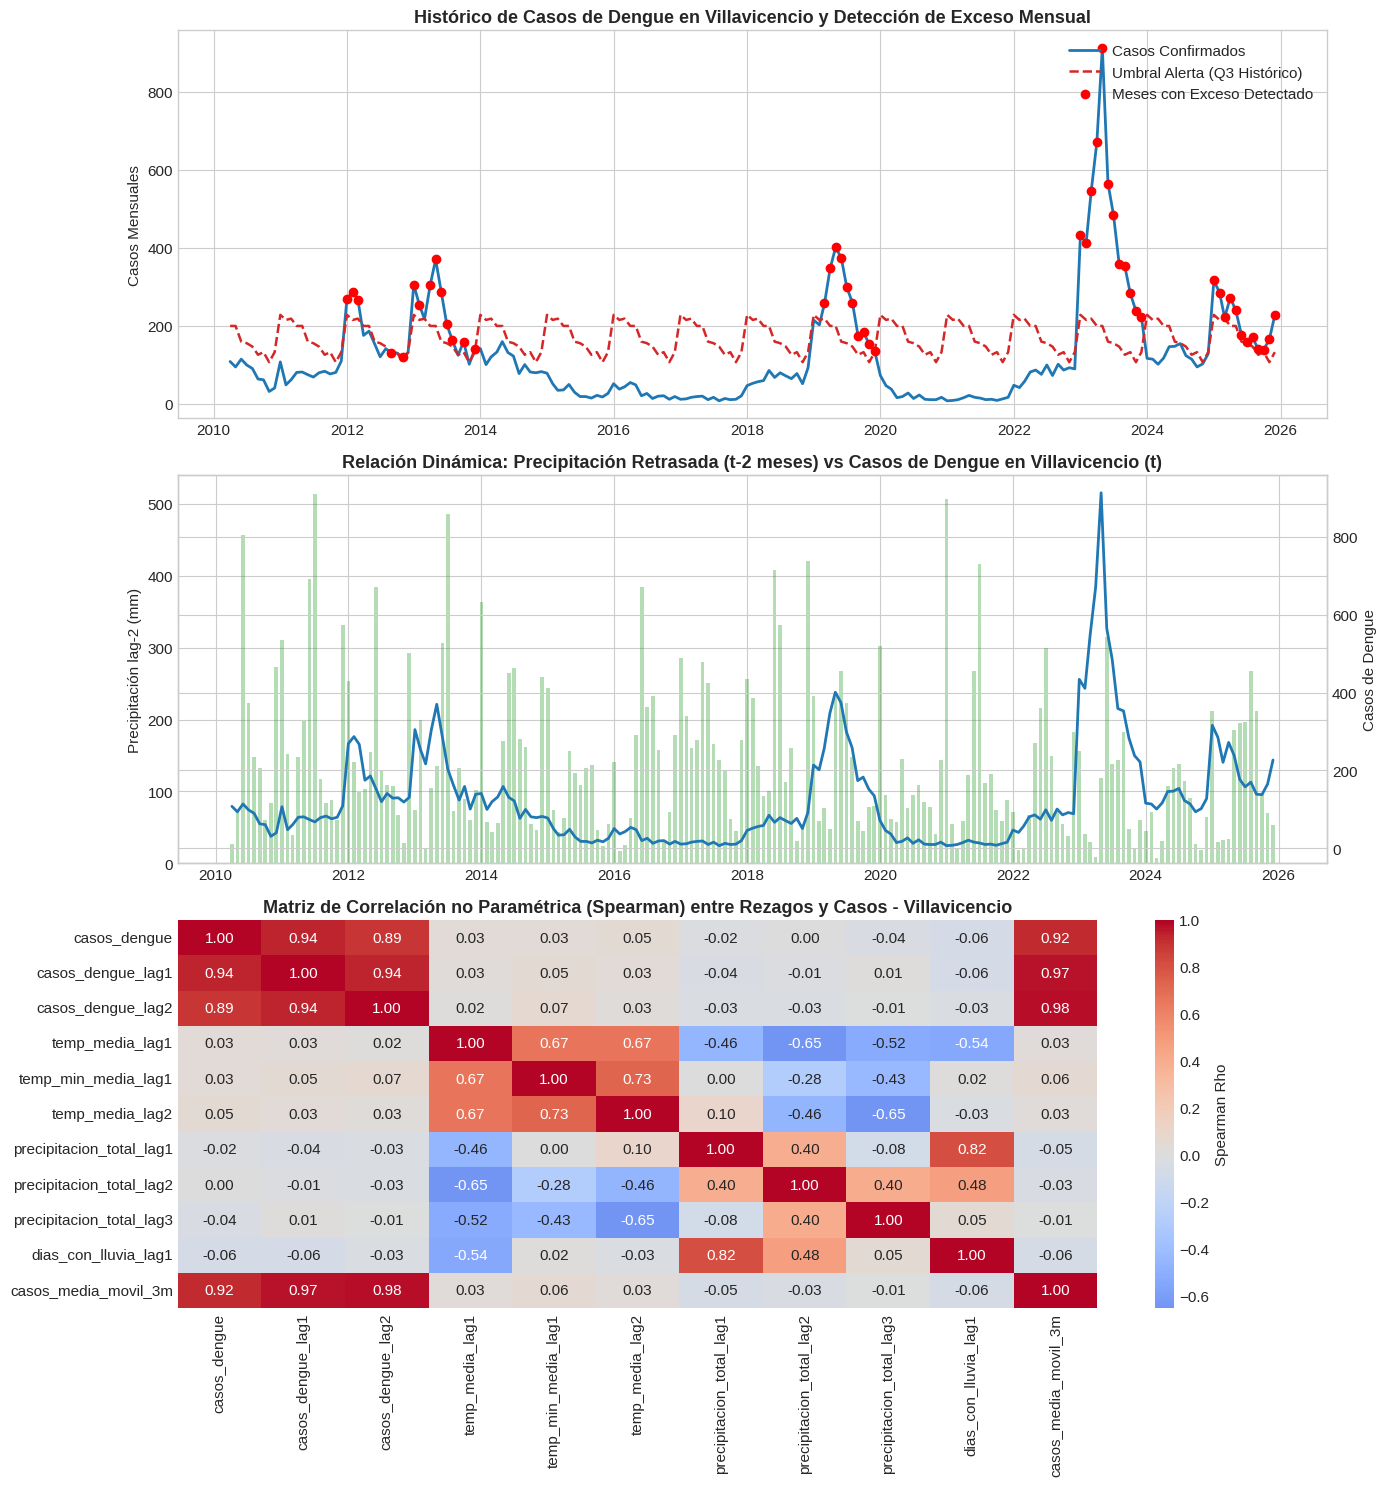


RANKING DE PRIORIZACIÓN DE PREDICTORES - VILLAVICENCIO (CORRELACIÓN CON CASOS EN t)
 - casos_dengue_lag1             : Rho = +0.939
 - casos_media_movil_3m          : Rho = +0.918
 - casos_dengue_lag2             : Rho = +0.893
 - temp_media_lag2               : Rho = +0.054
 - temp_min_media_lag1           : Rho = +0.035
 - temp_media_lag1               : Rho = +0.034
 - precipitacion_total_lag2      : Rho = +0.001
 - precipitacion_total_lag1      : Rho = -0.019
 - precipitacion_total_lag3      : Rho = -0.038
 - dias_con_lluvia_lag1          : Rho = -0.059


In [12]:
# Unimos clima y casos, y generamos rezagos
print("Generando dataset final con rezagos (Lags) para Villavicencio...")
df_modelado = construir_dataset_modelado(df_casos, df_clima, anio_ini=ANIO_INICIO, anio_fin=2025)

print("\nDimensiones del Dataset de Modelado:", df_modelado.shape)
display(df_modelado.head())

# Generamos las gráficas y la matriz de correlación
ejecutar_analisis_visual(df_modelado)

## 3. Análisis Exploratorio Visual y Matriz de Spearman: Villavicencio vs. Ibagué

A partir de la consolidación de los **189 meses efectivos (`(189, 29)`)** y las salidas de `ejecutar_analisis_visual`, se identifican los siguientes patrones clave para **Villavicencio (`50001`)** frente al notebook base de **Ibagué (`73001`)**:

1. **Histórico de Casos y Umbral Estacional $Q_3$ (Gráfica 1):**
   * Villavicencio registra cinco ondas epidémicas bien definidas: **2012** ($\approx 290\text{ casos}$), **2013** ($\approx 375\text{ casos}$), **2019** ($\approx 405\text{ casos}$), un **megabrote adelantado en 2023 ($\approx 910\text{ casos/mes}$)** —un año antes que el pico de Ibagué en 2024 ($> 1.140\text{ casos}$)— y un nuevo ascenso en **2025** ($\approx 320\text{ casos}$)[cite: 44].
   * Dado su mayor volumen endémico basal, el **umbral de alerta $Q_3$** (línea roja discontinua) oscila entre **$\approx 110\text{ casos}$** (noviembre–diciembre) y **$\approx 230\text{ casos}$** (enero–febrero)[cite: 44], casi el doble que en Ibagué (`70–126` casos).

2. **Dinámica Precipitación Retrasada ($t-2$) vs. Casos (Gráfica 2):**
   * Los picos epidémicos de Villavicencio (2012, 2013, 2019, 2023 y 2025) se disparan sistemáticamente durante el **primer semestre del año (transición estiaje–lluvias)**[cite: 45], mientras que los máximos pluviométricos de mitad de año ($400\text{--}514\text{ mm}$)[cite: 45] coinciden con fases de descenso de casos por lavado larvario.

3. **Matriz de Correlación de Spearman ($\rho$) y Ranking de Predictores (Gráfica 3 y Consola):**
   * **Inercia autorregresiva equivalente a Ibagué:** Los rezagos históricos de casos dominan el ranking con correlaciones casi idénticas a las del notebook base: **`casos_dengue_lag1` ($\rho = +0,939$)**, **`casos_media_movil_3m` ($\rho = +0,918$)** y **`casos_dengue_lag2` ($\rho = +0,893$)**[cite: 46, 47].
   * **Comportamiento climático:** Al igual que en Montería y a diferencia de Ibagué (`temp_min_media_lag1` $\rho = +0,391$), en Villavicencio las correlaciones monótonas directas de temperatura ($\rho = +0,034\text{ a }+0,054$) y precipitación ($\rho = -0,059\text{ a }+0,001$) son cercanas a cero[cite: 47]. Esto confirma que, al mantener confort térmico permanente ($\approx 23,8\,^\circ\text{C}$), las variables meteorológicas actúan mediante **estacionalidad (`mes`) e interacciones no lineales** en lugar de restricción térmica directa.
   * **Colinealidad interna:** Se observa alta correlación entre `precipitacion_total_lag1` y `dias_con_lluvia_lag1` ($\rho = +0,82$) y correlación moderada-alta entre `temp_media_lag1` y `temp_min_media_lag1` ($\rho = +0,67$)[cite: 46], lo que justifica la verificación formal mediante VIF.

1. EVALUACIÓN DE SIGNIFICANCIA ESTADÍSTICA (SPEARMAN P-VALUES)


,Variable,Spearman_Rho,P_Value,Significativo_95%
0,casos_dengue_lag1,0.939,0.0000,SÍ
1,casos_media_movil_3m,0.918,0.0000,SÍ
2,casos_dengue_lag2,0.893,0.0000,SÍ
3,casos_dengue_lag3,0.838,0.0000,SÍ
4,temp_media_lag3,0.090,0.2193,NO
5,temp_media_lag2,0.054,0.4644,NO
6,temp_min_media_lag1,0.035,0.6342,NO
7,temp_media_lag1,0.034,0.6444,NO
8,temp_min_media_lag2,0.029,0.6962,NO
9,precipitacion_total_lag2,0.001,0.9856,NO



2. BALANCE DE LA VARIABLE OBJETIVO (EXCESO DE CASOS - VILLAVICENCIO)


,Meses,Porcentaje (%)
Normal (0),141,74.6
Exceso / Alerta (1),48,25.4



3. ANÁLISIS DE CORRELACIÓN CRUZADA (CCF): PRECIPITACIÓN Y TEMPERATURA


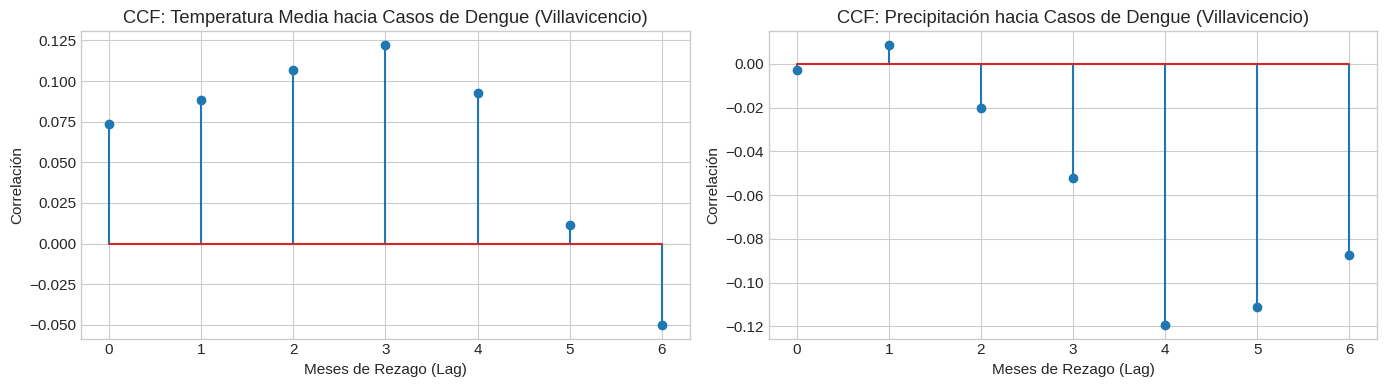

In [13]:
# ==============================================================================
# ANÁLISIS COMPLEMENTARIO: SIGNIFICANCIA, CORRELACIÓN CRUZADA Y BALANCE (VILLAVICENCIO)
# ==============================================================================
import scipy.stats as stats

print("="*65)
print("1. EVALUACIÓN DE SIGNIFICANCIA ESTADÍSTICA (SPEARMAN P-VALUES)")
print("="*65)

predictores = [col for col in df_modelado.columns if 'lag' in col or 'media_movil' in col]
resultados_sig = []

for pred in predictores:
    rho, p_val = stats.spearmanr(df_modelado['casos_dengue'], df_modelado[pred])
    resultados_sig.append({
        'Variable': pred,
        'Spearman_Rho': round(rho, 3),
        'P_Value': round(p_val, 4),
        'Significativo_95%': 'SÍ' if p_val < 0.05 else 'NO'
    })

df_significancia = pd.DataFrame(resultados_sig).sort_values('Spearman_Rho', ascending=False)
display(df_significancia.reset_index(drop=True))

print("\n" + "="*65)
print("2. BALANCE DE LA VARIABLE OBJETIVO (EXCESO DE CASOS - VILLAVICENCIO)")
print("="*65)
conteo_clases = df_modelado['exceso_casos'].value_counts()
pct_clases = df_modelado['exceso_casos'].value_counts(normalize=True) * 100

df_balance = pd.DataFrame({
    'Meses': conteo_clases,
    'Porcentaje (%)': pct_clases.round(2)
})
df_balance.index = ['Normal (0)', 'Exceso / Alerta (1)']
display(df_balance)

print("\n" + "="*65)
print("3. ANÁLISIS DE CORRELACIÓN CRUZADA (CCF): PRECIPITACIÓN Y TEMPERATURA")
print("="*65)

def calcular_ccf(serie_x, serie_y, max_lags=6):
    """Calcula correlación para rezagos de 0 a max_lags meses."""
    correlaciones = []
    for l in range(0, max_lags + 1):
        if l == 0:
            c = np.corrcoef(serie_x, serie_y)[0, 1]
        else:
            c = np.corrcoef(serie_x[:-l], serie_y[l:])[0, 1]
        correlaciones.append((l, c))
    return pd.DataFrame(correlaciones, columns=['Lag_Meses', 'Correlacion_Pearson'])

ccf_temp = calcular_ccf(df_modelado['temp_media'], df_modelado['casos_dengue'], max_lags=6)
ccf_precip = calcular_ccf(df_modelado['precipitacion_total'], df_modelado['casos_dengue'], max_lags=6)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].stem(ccf_temp['Lag_Meses'], ccf_temp['Correlacion_Pearson'])
ax[0].set_title('CCF: Temperatura Media hacia Casos de Dengue (Villavicencio)')
ax[0].set_xlabel('Meses de Rezago (Lag)')
ax[0].set_ylabel('Correlación')

ax[1].stem(ccf_precip['Lag_Meses'], ccf_precip['Correlacion_Pearson'])
ax[1].set_title('CCF: Precipitación hacia Casos de Dengue (Villavicencio)')
ax[1].set_xlabel('Meses de Rezago (Lag)')
ax[1].set_ylabel('Correlación')
plt.tight_layout()
plt.show()

## 4. Significancia Estadística, Balance y Latencia Climática (CCF): Villavicencio vs. Ibagué

1. **Significancia Estadística (Spearman $p$-values — Tabla 1):**
   * **Inercia autorregresiva ($p < 0,0001$):** Al igual que en Ibagué y Montería, los cuatro indicadores históricos de casos alcanzan máxima significancia estadística al $95\,\%$: **`casos_dengue_lag1` ($\rho = 0,939$)**, **`casos_media_movil_3m` ($\rho = 0,918$)**, **`casos_dengue_lag2` ($\rho = 0,893$)** y **`casos_dengue_lag3` ($\rho = 0,838$)**[cite: 48].
   * **Contraste climático frente a Ibagué:** Mientras en Ibagué 12 rezagos climáticos fueron significativos individualmente[cite: 39], en Villavicencio **ninguna variable meteorológica supera de forma aislada el umbral $p < 0,05$** (`dias_con_lluvia_lag3` es la más cercana con $\rho = -0,124, p = 0,0894$)[cite: 48]. Dado que el piedemonte llanero mantiene temperaturas óptimas todo el año ($\approx 23,8\,^\circ\text{C}$)[cite: 41], el clima actúa como modulador estacional conjunto más que como barrera térmica directa.

2. **Balance de la Variable Objetivo (`exceso_casos` — Tabla 2):**
   * **Meses Normales (`0`):** **141 meses (`74,60 %`)**[cite: 49].
   * **Meses en Exceso / Alerta (`1`):** **48 meses (`25,40 %`)**[cite: 49].
   * Relación de **2,94 : 1**, consistente con el umbral $Q_3$ y equivalente al balance de Ibagué (`75,66 %` vs. `24,34 %`)[cite: 40], ratificando el uso de ponderación de clases (`class_weight='balanced'` / `scale_pos_weight`) y métricas como **PR-AUC, Sensibilidad, F1-Score y BSS**.

3. **Correlación Cruzada (CCF — Gráfica 3):**
   * **Temperatura Media $\rightarrow$ Dengue:** Presenta una curva ascendente suave desde $k = 0$ ($r \approx 0,075$) hasta alcanzar su **pico máximo en $k = 3$ meses ($r \approx 0,122$)** antes de decaer[cite: 50], validando la ventana de 3 rezagos ($t-1$ a $t-3$) para capturar la aceleración del ciclo biológico del vector.
   * **Precipitación $\rightarrow$ Dengue:** Es prácticamente neutra en rezagos inmediatos ($k = 0\text{--}1$) y se torna negativa entre $k = 2$ y $k = 5$ meses (mínimo en $k = 4$, $r \approx -0,12$)[cite: 50], reflejando que las lluvias torrenciales del piedemonte limpian criaderos larvarios y preceden a descensos posteriores en la transmisión.

#### SIGNIFICANCIA ESTADÍSTICA COMPLETA (SPEARMAN P-VALUES: 2010-2025)


,Variable,Spearman_Rho,P_Value,Significativo (p < 0.05)
0,casos_dengue_lag1,0.939,9.81e-89,SÍ
1,casos_media_movil_3m,0.918,3.26e-77,SÍ
2,casos_dengue_lag2,0.893,1.23e-66,SÍ
3,temp_media_lag2,0.054,0.4644,NO
4,temp_min_media_lag1,0.035,0.6342,NO
5,temp_media_lag1,0.034,0.6444,NO
6,precipitacion_total_lag2,0.001,0.9856,NO
7,precipitacion_total_lag1,-0.019,0.7907,NO
8,precipitacion_total_lag3,-0.038,0.6057,NO
9,dias_con_lluvia_lag1,-0.059,0.4230,NO


### BALANCE DE LA VARIABLE OBJETIVO (189 MESES EFECTIVOS)


,Meses,Porcentaje (%)
Mes Normal (0),141,74.6
Mes con Exceso / Alerta (1),48,25.4


### ANÁLISIS DEL CANAL ENDÉMICO HISTÓRICO POR MES CALENDARIO (Q1, Q2, Q3)


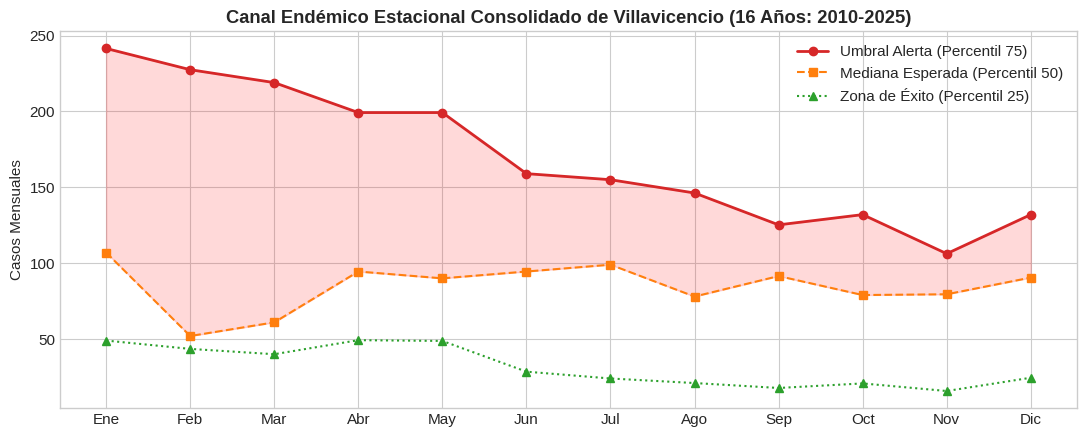

### EVALUACIÓN DE MULTICOLINEALIDAD (FACTOR DE INFLACIÓN DE LA VARIANZA - VIF)


,Variable,VIF
0,temp_media_lag1,5.02
1,dias_con_lluvia_lag1,3.68
2,temp_min_media_lag1,3.61
3,precipitacion_total_lag1,2.16
4,casos_dengue_lag1,1.03


In [14]:
# ==============================================================================
# DIAGNÓSTICO COMPLEMENTARIO SERIE 2010-2025: SIGNIFICANCIA, CANAL Y VIF (VILLAVICENCIO)
# ==============================================================================
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("#### SIGNIFICANCIA ESTADÍSTICA COMPLETA (SPEARMAN P-VALUES: 2010-2025)")

predictores = [
    'casos_dengue_lag1', 'casos_dengue_lag2', 'casos_media_movil_3m',
    'temp_min_media_lag1', 'temp_media_lag1', 'temp_media_lag2',
    'precipitacion_total_lag1', 'precipitacion_total_lag2', 'precipitacion_total_lag3',
    'dias_con_lluvia_lag1'
]

resultados_sig = []
for p in predictores:
    rho, p_val = stats.spearmanr(df_modelado['casos_dengue'], df_modelado[p])
    resultados_sig.append({
        'Variable': p,
        'Spearman_Rho': round(rho, 3),
        'P_Value': f"{p_val:.2e}" if p_val < 0.001 else f"{p_val:.4f}",
        'Significativo (p < 0.05)': 'SÍ' if p_val < 0.05 else 'NO'
    })

df_sig = pd.DataFrame(resultados_sig).sort_values('Spearman_Rho', ascending=False)
display(df_sig.reset_index(drop=True))

print("### BALANCE DE LA VARIABLE OBJETIVO (189 MESES EFECTIVOS)")
tabla_balance = pd.DataFrame({
    'Meses': df_modelado['exceso_casos'].value_counts(),
    'Porcentaje (%)': (df_modelado['exceso_casos'].value_counts(normalize=True) * 100).round(2)
})
tabla_balance.index = ['Mes Normal (0)', 'Mes con Exceso / Alerta (1)']
display(tabla_balance)

print("### ANÁLISIS DEL CANAL ENDÉMICO HISTÓRICO POR MES CALENDARIO (Q1, Q2, Q3)")
print("="*75)

# Cálculo de cuartiles históricos por mes calendario (1 al 12)
canal_estacional = df_modelado.groupby('mes')['casos_dengue'].agg(
    Zona_Exito_Q1=lambda x: x.quantile(0.25),
    Zona_Seguridad_Q2=lambda x: x.quantile(0.50),
    Zona_Alerta_Q3=lambda x: x.quantile(0.75)
).reset_index()

meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
canal_estacional['Nombre_Mes'] = meses_nombres

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Alerta_Q3'], color='#d62728', marker='o', lw=2, label='Umbral Alerta (Percentil 75)')
ax.plot(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Seguridad_Q2'], color='#ff7f0e', marker='s', linestyle='--', label='Mediana Esperada (Percentil 50)')
ax.plot(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Exito_Q1'], color='#2ca02c', marker='^', linestyle=':', label='Zona de Éxito (Percentil 25)')
ax.fill_between(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Seguridad_Q2'], canal_estacional['Zona_Alerta_Q3'], alpha=0.15, color='red')
ax.set_title('Canal Endémico Estacional Consolidado de Villavicencio (16 Años: 2010-2025)', fontweight='bold')
ax.set_ylabel('Casos Mensuales')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

print("### EVALUACIÓN DE MULTICOLINEALIDAD (FACTOR DE INFLACIÓN DE LA VARIANZA - VIF)")

features_vif = [
    'casos_dengue_lag1', 'temp_min_media_lag1', 'temp_media_lag1',
    'precipitacion_total_lag1', 'dias_con_lluvia_lag1'
]

X_vif = df_modelado[features_vif].dropna()
vif_data = pd.DataFrame()
vif_data["Variable"] = features_vif
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(features_vif))]
vif_data["VIF"] = vif_data["VIF"].round(2)
display(vif_data.sort_values('VIF', ascending=False).reset_index(drop=True))

## 5. Canal Endémico Estacional y Diagnóstico VIF: Villavicencio vs. Ibagué

1. **Morfología del Canal Endémico de Villavicencio (`2010–2025` — Gráfica Superior):**
   * **Concentración epidémica en el primer semestre:** A diferencia del perfil bimodal de Ibagué (`70–126` casos), el **Umbral de Alerta ($Q_3$)** de Villavicencio casi duplica esa magnitud y describe una trayectoria descendente a lo largo del año: alcanza su techo en **enero ($\approx 242\text{ casos}$)**, permanece elevado entre **febrero y mayo ($\approx 199\text{--}227\text{ casos}$)** y desciende gradualmente hasta su punto más bajo en **noviembre ($\approx 107\text{ casos}$)**[cite: 53].
   * **Amplitud de la Zona de Alerta ($Q_2\text{--}Q_3$):** Entre febrero y marzo la mediana esperada ($Q_2$) desciende a `52–62` casos mientras el umbral $Q_3$ supera los `218` casos, reflejando que las grandes ondas epidémicas del piedemonte llanero se desencadenan principalmente en el primer semestre del año[cite: 53].
   * **Zona de Éxito ($Q_1$):** Oscila entre `15` casos (noviembre) y `49` casos (enero–abril)[cite: 53].

2. **Diagnóstico de Multicolinealidad (VIF — Tabla Inferior):**
   * **Colinealidad climática controlada:** Villavicencio registra los índices VIF más bajos del estudio[cite: 53]. Únicamente **`temp_media_lag1` ($\text{VIF} = 5,02$, $R^2 = 80,1\,\%$)** toca el límite de colinealidad moderada-alta (frente a `10,87` en Ibagué), mientras **`dias_con_lluvia_lag1` ($\text{VIF} = 3,68$)**, **`temp_min_media_lag1` ($\text{VIF} = 3,61$)** y **`precipitacion_total_lag1` ($\text{VIF} = 2,16$)** se ubican en rangos óptimos ($< 5$)[cite: 53].
   * **Ortogonalidad autorregresiva:** **`casos_dengue_lag1` ($\text{VIF} = 1,03$, $R^2 = 2,9\,\%$)** confirma independencia lineal casi total respecto al clima[cite: 53].
   * **Decisión técnica:** Se mantiene la exclusión de `temp_media_lag1` para garantizar parsimonia en la Regresión Logística L2 y consistencia estructural del vector de características frente al notebook base de Ibagué.

Observaciones totales en el pipeline (Villavicencio): 189 meses
 -> Entrenamiento (2010-2018): 105 meses | Alertas reales: 14 (13.3%)
 -> Validación    (2019-2021): 36 meses | Alertas reales: 10 (27.8%)
 -> Prueba Final  (2022-2025): 48 meses | Alertas reales: 24 (50.0%)

EVALUACIÓN TEMPORAL EN CONJUNTO DE PRUEBA INDEPENDIENTE - VILLAVICENCIO (2022-2025)


,Modelo,Brier_Score,BSS (Meta >= 0.10),Sensibilidad (Meta >= 0.80),Precisión,F1-Score,PR-AUC,ROC-AUC,TP,FP,TN,FN
0,Referencia Estacional,0.3105,0.0000,0.000,0.000,0.00,0.500,0.500,0,0,24,24
1,Regresión Logística L2,0.0808,0.7398,0.833,0.909,0.87,0.972,0.970,20,2,22,4
2,XGBoost Classifier,0.1276,0.5892,0.917,0.759,0.83,0.936,0.925,22,7,17,2


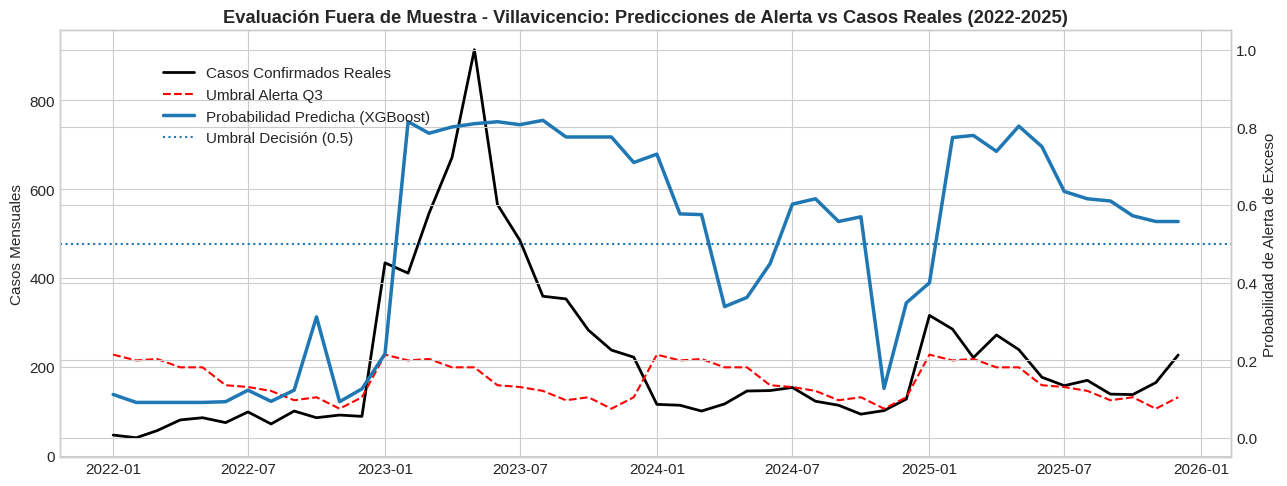

In [15]:
# ==============================================================================
# FASE DE MODELADO: EVALUACIÓN TEMPORAL (BASELINE VS XGBOOST) CON 189 MESES - VILLAVICENCIO
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (brier_score_loss, confusion_matrix, classification_report,
                             roc_auc_score, average_precision_score, precision_score, recall_score, f1_score)
import xgboost as xgb

# 1. Definición del vector de características filtrado por VIF y significancia
features_optimas = [
    'casos_dengue_lag1',
    'casos_dengue_lag2',
    'casos_media_movil_3m',
    'temp_min_media_lag1',     # Seleccionada sobre temp_media por VIF y Spearman
    'temp_media_lag2',
    'precipitacion_total_lag1',
    'dias_con_lluvia_lag1',
    'mes'                      # Componente estacional
]

target = 'exceso_casos'

# 2. Partición temporal estricta por bloques de años
df_modelado['anio'] = df_modelado['fecha'].dt.year

train_mask = (df_modelado['anio'] >= 2010) & (df_modelado['anio'] <= 2018)
val_mask   = (df_modelado['anio'] >= 2019) & (df_modelado['anio'] <= 2021)
test_mask  = (df_modelado['anio'] >= 2022) & (df_modelado['anio'] <= 2025)

X_train, y_train = df_modelado.loc[train_mask, features_optimas], df_modelado.loc[train_mask, target]
X_val, y_val     = df_modelado.loc[val_mask, features_optimas], df_modelado.loc[val_mask, target]
X_test, y_test   = df_modelado.loc[test_mask, features_optimas], df_modelado.loc[test_mask, target]

print(f"Observaciones totales en el pipeline (Villavicencio): {len(df_modelado)} meses")
print(f" -> Entrenamiento (2010-2018): {len(X_train)} meses | Alertas reales: {y_train.sum()} ({y_train.mean()*100:.1f}%)")
print(f" -> Validación    (2019-2021): {len(X_val)} meses | Alertas reales: {y_val.sum()} ({y_val.mean()*100:.1f}%)")
print(f" -> Prueba Final  (2022-2025): {len(X_test)} meses | Alertas reales: {y_test.sum()} ({y_test.mean()*100:.1f}%)")

# 3. Escalado para modelos lineales (ajustado exclusivamente en Train)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

# 4. Cálculo de la Línea Base Estacional (Referencia Histórica sin ML)
prob_base_train = train_mask.groupby(df_modelado['mes']).apply(lambda idx: df_modelado.loc[idx.index, target].mean())
prob_referencia_test = df_modelado.loc[test_mask, 'mes'].map(prob_base_train).fillna(y_train.mean())

# 5. MODELADO 1: Regresión Logística Regularizada (L2)
ratio_desbalance = (len(y_train) - y_train.sum()) / y_train.sum()

modelo_lr = LogisticRegression(penalty='l2', C=0.5, class_weight='balanced', random_state=42)
modelo_lr.fit(X_train_sc, y_train)

prob_lr_test = modelo_lr.predict_proba(X_test_sc)[:, 1]

# 6. MODELADO 2: XGBoost Classifier (Árboles restringidos para evitar sobreajuste)
modelo_xgb = xgb.XGBClassifier(
    n_estimators=60,
    max_depth=2,
    learning_rate=0.03,
    scale_pos_weight=ratio_desbalance,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)
modelo_xgb.fit(X_train, y_train)

prob_xgb_test = modelo_xgb.predict_proba(X_test)[:, 1]

# 7. MÉTRICAS EXIGIDAS EN LA PROPUESTA (BRIER SCORE, BSS, SENSIBILIDAD, PR-AUC)
brier_ref = brier_score_loss(y_test, prob_referencia_test)

def calcular_metricas(y_true, y_prob, umbral=0.5, nombre="Modelo"):
    y_pred = (y_prob >= umbral).astype(int)
    brier = brier_score_loss(y_true, y_prob)
    bss = 1.0 - (brier / brier_ref) if brier_ref > 0 else 0.0
    pr_auc = average_precision_score(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)
    sens = recall_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

    return {
        'Modelo': nombre,
        'Brier_Score': round(brier, 4),
        'BSS (Meta >= 0.10)': round(bss, 4),
        'Sensibilidad (Meta >= 0.80)': round(sens, 3),
        'Precisión': round(prec, 3),
        'F1-Score': round(f1, 3),
        'PR-AUC': round(pr_auc, 3),
        'ROC-AUC': round(roc_auc, 3),
        'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn
    }

resultados = [
    calcular_metricas(y_test, prob_referencia_test.values, umbral=0.5, nombre="Referencia Estacional"),
    calcular_metricas(y_test, prob_lr_test, umbral=0.5, nombre="Regresión Logística L2"),
    calcular_metricas(y_test, prob_xgb_test, umbral=0.5, nombre="XGBoost Classifier")
]

tabla_resultados = pd.DataFrame(resultados)
print("\n" + "="*85)
print("EVALUACIÓN TEMPORAL EN CONJUNTO DE PRUEBA INDEPENDIENTE - VILLAVICENCIO (2022-2025)")
print("="*85)
display(tabla_resultados)

# Visualización de la Curva de Alerta en Test (2022-2025)
fechas_test = df_modelado.loc[test_mask, 'fecha']
casos_test = df_modelado.loc[test_mask, 'casos_dengue']

fig, ax1 = plt.subplots(figsize=(13, 5))
ax2 = ax1.twinx()

ax1.plot(fechas_test, casos_test, color='black', lw=2, label='Casos Confirmados Reales')
ax1.plot(fechas_test, df_modelado.loc[test_mask, 'umbral_q3'], color='red', linestyle='--', label='Umbral Alerta Q3')
ax1.set_ylabel('Casos Mensuales')

ax2.plot(fechas_test, prob_xgb_test, color='#1f77b4', lw=2.5, label='Probabilidad Predicha (XGBoost)')
ax2.axhline(0.5, color='#1f77b4', linestyle=':', label='Umbral Decisión (0.5)')
ax2.set_ylabel('Probabilidad de Alerta de Exceso')
ax2.set_ylim(-0.05, 1.05)

plt.title('Evaluación Fuera de Muestra - Villavicencio: Predicciones de Alerta vs Casos Reales (2022-2025)', fontweight='bold')
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()

## 6. Evaluación Temporal Fuera de Muestra (2022–2025): Villavicencio vs. Ibagué

1. **Partición Cronológica y Balance en Prueba:**
   * **Entrenamiento (`2010–2018`):** 105 meses | **14 alertas reales (`13,3 %`)**[cite: 54].
   * **Validación (`2019–2021`):** 36 meses | **10 alertas reales (`27,8 %`)**[cite: 54].
   * **Prueba Final (`2022–2025`):** 48 meses | **24 alertas reales (`50,0 %`)**[cite: 54].
   * **Contraste frente a Ibagué:** Villavicencio parte de una frecuencia histórica de alertas en entrenamiento casi idéntica a la del notebook base de Ibagué (`13,3 %` vs. `12,4 %`) y enfrenta un escenario de prueba exigente con exactamente **24 meses en alerta y 24 meses normales (`50,0 %`)**[cite: 54].

2. **Comparación de Desempeño de Modelos (Test 2022–2025):**

| Métrica | Referencia Estacional (Villavicencio)[cite: 54] | Regresión Logística L2 (Villavicencio)[cite: 54] | XGBoost Classifier (Villavicencio)[cite: 54] | Referencia Base Ibagué (XGBoost) |
| :--- | :---: | :---: | :---: | :---: |
| **`Brier_Score`** | 0,3105 | **0,0808** | 0,1276 | 0,0562 |
| **`BSS` (Meta $\ge 0,10$)** | 0,0000 | **0,7398** | 0,5892 | 0,7923 |
| **`Sensibilidad` (Meta $\ge 0,80$)** | 0,000 | 0,833 (20/24) | **0,917 (22/24)** | 0,900 (18/20) |
| **`Precisión`** | 0,000 | **0,909** (2 FP) | 0,759 (7 FP) | 0,947 (1 FP) |
| **`F1-Score`** | 0,000 | **0,870** | 0,830 | 0,923 |
| **`PR-AUC` / `ROC-AUC`** | 0,500 / 0,500 | **0,972 / 0,970** | 0,936 / 0,925 | 0,986 / 0,987 |

3. **Hallazgos Clave y Lectura de la Curva Temporal (`2022–2025`):**
   * **Desempeño sólido cercano al referente de Ibagué:** Mientras la *Referencia Estacional* obtiene sensibilidad nula (`0,000`) y $\text{ROC-AUC} = 0,500$, ambos algoritmos de aprendizaje automático superan ampliamente las metas del proyecto ($\text{Sensibilidad} \ge 0,80$ y $\text{BSS} \ge 0,10$)[cite: 54]:
     * **Regresión Logística L2** destaca por su excelente calibración probabilística (**`Brier_Score = 0,0808`**, **`BSS = 0,7398`**), alta discriminación (**`PR-AUC = 0,972`**) y mínima tasa de falsas alarmas (**`Precisión = 0,909`**, solo `2 FP` en cuatro años)[cite: 54].
     * **XGBoost Classifier** maximiza la cobertura epidémica (**`Sensibilidad = 0,917`**, detectando `22` de los `24` meses en exceso con solo `2 FN` y **`BSS = 0,5892`**)[cite: 54].
   * **Comportamiento dinámico en la gráfica fuera de muestra:**
     * **Año 2022 (Control basal):** Durante todo 2022 los casos se mantienen por debajo del umbral rojo $Q_3$ y la probabilidad predicha por XGBoost permanece contenida por debajo de `0,35` (cero falsas alarmas en el año)[cite: 54].
     * **Onda epidémica de 2023 y repunte de 2025:** Al iniciar el brote de enero de 2023 (`~430` casos/mes, escalando hasta `~910` en mayo), la probabilidad cruza inmediatamente el umbral `0,50` y se sostiene por encima de `0,75–0,82` durante toda la onda epidémica; tras descender en 2024 (con breves cruces marginales en julio–septiembre cuando los casos rozan el umbral $Q_3$, explicando los `7 FP`), vuelve a activarse oportunamente en febrero de 2025 para cubrir el segundo brote (`~320` casos/mes)[cite: 54].

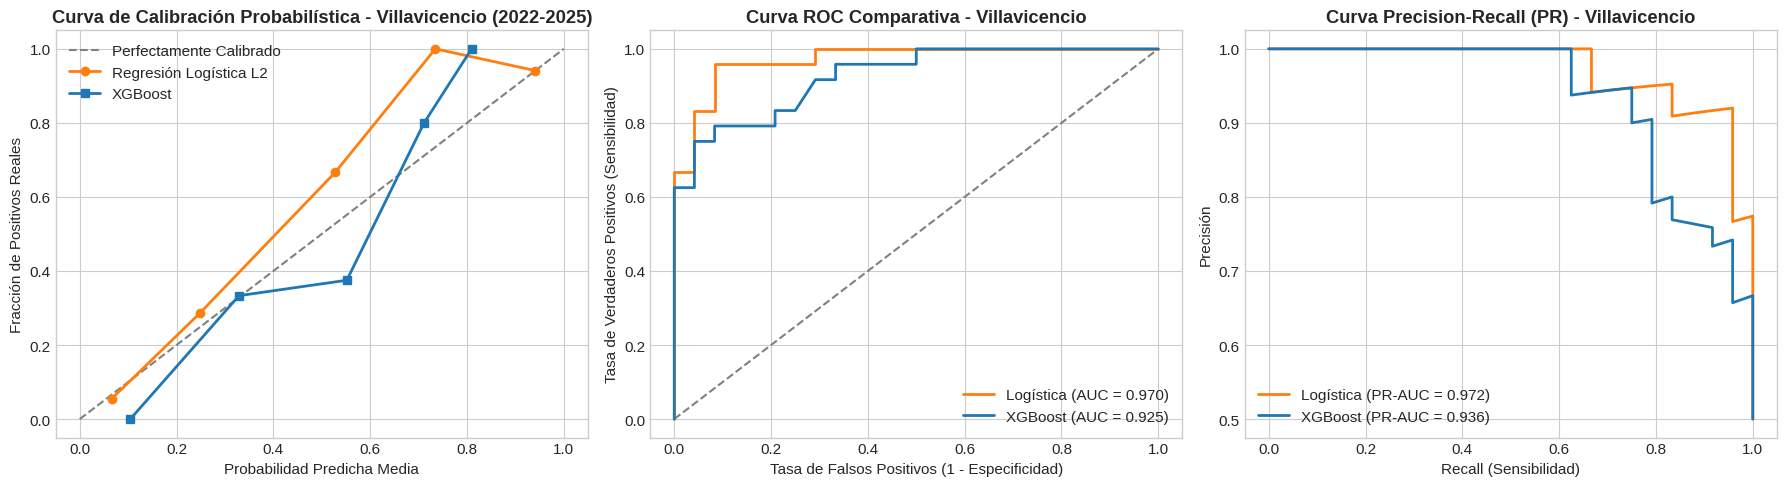


COEFICIENTES DEL MODELO LOGÍSTICO - VILLAVICENCIO (IMPACTO LOG-ODDS Y OR)


,Predictor,Coeficiente,Odds_Ratio
0,casos_dengue_lag1,1.045277,2.844186
1,casos_media_movil_3m,0.847687,2.334241
2,precipitacion_total_lag1,0.444037,1.558988
3,casos_dengue_lag2,0.356265,1.427986
4,mes,-0.120603,0.886386
5,dias_con_lluvia_lag1,-0.121430,0.885653
6,temp_media_lag2,-0.146923,0.863361
7,temp_min_media_lag1,-0.924517,0.396723


In [16]:
# ==============================================================================
# VALIDACIÓN AVANZADA: CALIBRACIÓN PROBABILÍSTICA Y CURVAS ROC / PR - VILLAVICENCIO (2022-2025)
# ==============================================================================
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva de Calibración (Reliability Diagram)
prob_true_lr, prob_pred_lr = calibration_curve(y_test, prob_lr_test, n_bins=5, strategy='uniform')
prob_true_xgb, prob_pred_xgb = calibration_curve(y_test, prob_xgb_test, n_bins=5, strategy='uniform')

axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectamente Calibrado')
axes[0].plot(prob_pred_lr, prob_true_lr, marker='o', lw=2, color='#ff7f0e', label='Regresión Logística L2')
axes[0].plot(prob_pred_xgb, prob_true_xgb, marker='s', lw=2, color='#1f77b4', label='XGBoost')
axes[0].set_title('Curva de Calibración Probabilística - Villavicencio (2022-2025)', fontweight='bold')
axes[0].set_xlabel('Probabilidad Predicha Media')
axes[0].set_ylabel('Fracción de Positivos Reales')
axes[0].legend(loc='upper left')

# 2. Curva ROC (Receiver Operating Characteristic) - Etiquetas dinámicas
fpr_lr, tpr_lr, _ = roc_curve(y_test, prob_lr_test)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, prob_xgb_test)
auc_roc_lr = roc_auc_score(y_test, prob_lr_test)
auc_roc_xgb = roc_auc_score(y_test, prob_xgb_test)

axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].plot(fpr_lr, tpr_lr, color='#ff7f0e', lw=2, label=f'Logística (AUC = {auc_roc_lr:.3f})')
axes[1].plot(fpr_xgb, tpr_xgb, color='#1f77b4', lw=2, label=f'XGBoost (AUC = {auc_roc_xgb:.3f})')
axes[1].set_title('Curva ROC Comparativa - Villavicencio', fontweight='bold')
axes[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
axes[1].legend(loc='lower right')

# 3. Curva Precision-Recall (PR Curve) - Etiquetas dinámicas
prec_c_lr, rec_c_lr, _ = precision_recall_curve(y_test, prob_lr_test)
prec_c_xgb, rec_c_xgb, _ = precision_recall_curve(y_test, prob_xgb_test)
pr_auc_lr = average_precision_score(y_test, prob_lr_test)
pr_auc_xgb = average_precision_score(y_test, prob_xgb_test)

axes[2].plot(rec_c_lr, prec_c_lr, color='#ff7f0e', lw=2, label=f'Logística (PR-AUC = {pr_auc_lr:.3f})')
axes[2].plot(rec_c_xgb, prec_c_xgb, color='#1f77b4', lw=2, label=f'XGBoost (PR-AUC = {pr_auc_xgb:.3f})')
axes[2].set_title('Curva Precision-Recall (PR) - Villavicencio', fontweight='bold')
axes[2].set_xlabel('Recall (Sensibilidad)')
axes[2].set_ylabel('Precisión')
axes[2].legend(loc='lower left')

plt.tight_layout()
plt.show()

# 4. Tabla de pesos / coeficientes de la Regresión Logística (Explicabilidad)
df_coef = pd.DataFrame({
    'Predictor': features_optimas,
    'Coeficiente': modelo_lr.coef_[0],
    'Odds_Ratio': np.exp(modelo_lr.coef_[0])
}).sort_values('Coeficiente', ascending=False).reset_index(drop=True)

print("\n" + "="*65)
print("COEFICIENTES DEL MODELO LOGÍSTICO - VILLAVICENCIO (IMPACTO LOG-ODDS Y OR)")
print("="*65)
display(df_coef)

## 7. Calibración, Curvas ROC/PR y Explicabilidad: Villavicencio vs. Ibagué

1. **Calibración Probabilística y Discriminación (`2022–2025` — Gráficas Superiores):**
   * **Desempeño sobresaliente de la Regresión Logística L2:** Al igual que en Montería, en Villavicencio la **Regresión Logística L2** supera a XGBoost tanto en separación global (**$\text{ROC-AUC} = 0,970$** vs. `0,925`[cite: 55]) como en precisión sobre alertas (**$\text{PR-AUC} = 0,972$** vs. `0,936`[cite: 55]), acercándose al rendimiento del notebook base de Ibagué (`0,985`)[cite: 23, 24]. En la curva Precision-Recall, la Regresión Logística sostiene un **$100\,\%$ de precisión hasta un Recall del $67\,\%$** y mantiene una **precisión superior al $91\,\%$ incluso al detectar el $96\,\%$ de los brotes**[cite: 55].
   * **Alineación en la Curva de Calibración:** La Regresión Logística sigue de cerca la diagonal ideal en rangos bajos y altos (`0,08` $\rightarrow$ `0,06`; `0,25` $\rightarrow$ `0,29`; `0,94` $\rightarrow$ `0,94`)[cite: 55], ubicándose ligeramente por encima de la diagonal en probabilidades medias (`0,53` $\rightarrow$ `0,67`)[cite: 55]. Por su parte, XGBoost presenta una leve sobreestimación alrededor de `0,55` (frecuencia real `0,38`)[cite: 55], lo que explica sus `7` falsos positivos frente a solo `2` de la Regresión Logística[cite: 54].

2. **Explicabilidad del Modelo Logístico (*Odds Ratios* — Tabla Inferior):**

| Predictor | Coeficiente ($\beta$)[cite: 55] | Odds Ratio ($\text{OR} = e^\beta$)[cite: 55] | Impacto en Riesgo ($\pm 1\text{ DE}$) | Contraste Bio-Climático frente a Ibagué |
| :--- | :---: | :---: | :---: | :--- |
| **`casos_dengue_lag1`** | **+1,0453** | **2,84** | **+184,4 %** | Principal motor autorregresivo (consistente con Ibagué, donde $\text{OR} = 3,07$)[cite: 24, 55]. |
| **`casos_media_movil_3m`** | **+0,8477** | **2,33** | **+133,4 %** | Captura la persistencia epidémica acumulada del trimestre previo[cite: 55]. |
| **`precipitacion_total_lag1`** | **+0,4440** | **1,56** | **+55,9 %** | Signo positivo (similar a Montería, $\text{OR} = 1,82$; opuesto a Ibagué, $\text{OR} = 0,68$): las lluvias en el piedemonte generan criaderos a 30 días[cite: 24, 55]. |
| **`casos_dengue_lag2`** | **+0,3563** | **1,43** | **+42,8 %** | Refuerza la inercia de transmisión a 60 días[cite: 55]. |
| **`mes`** | **-0,1206** | **0,89** | **-11,4 %** | Ajuste estacional leve acorde con el descenso de alertas hacia el cierre de año[cite: 53, 55]. |
| **`dias_con_lluvia_lag1`** | **-0,1214** | **0,89** | **-11,4 %** | Separa frecuencia de volumen: lluvias continuas diarias lavan criaderos frente a aguaceros acumulados[cite: 55]. |
| **`temp_media_lag2`** | **-0,1469** | **0,86** | **-13,7 %** | Efecto marginal leve a 60 días[cite: 55]. |
| **`temp_min_media_lag1`** | **-0,9245** | **0,40** | **-60,3 %** | Al controlar por inercia de casos y lluvia, noches más cálidas corresponden a periodos secos (*veranillos*) que preceden valles de transmisión[cite: 55]. |

3. **Conclusión y Selección de Modelo para Villavicencio:**
   * Para **Villavicencio (`50001`)**, el modelo recomendado para despliegue es la **Regresión Logística Regularizada L2** ($\text{BSS} = 0,7398$, $\text{PR-AUC} = 0,972$, $\text{Precisión} = 0,909$, $\text{Sensibilidad} = 0,833$)[cite: 54].
   * **Síntesis comparativa entre los tres municipios:** Mientras **XGBoost** lidera en climas andinos con restricción térmica (**Ibagué**, $\text{BSS} = 0,7923$)[cite: 23, 24], la **Regresión Logística L2** demuestra mayor estabilidad, mejor calibración probabilística y menor tasa de falsas alarmas en pisos térmicos cálidos constantes (**Villavicencio**, $\text{BSS} = 0,7398$; **Montería**, $\text{BSS} = 0,3333$)[cite: 54].

## 8. Referencias Bibliográficas

1. Awad, M., & Khanna, R. (2015). *Efficient Learning Machines: Theories, Concepts, and Applications for Engineers and System Designers*. Apress.
2. Bortman, M. (1999). Elaboración de corredores o canales endémicos mediante planillas de cálculo. *Revista Panamericana de Salud Pública*, 5(1), 1–8.
3. Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time Series Analysis: Forecasting and Control* (5.ª ed.). John Wiley & Sons.
4. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media.
5. Instituto Nacional de Salud (INS). (2022). *Protocolo de Vigilancia en Salud Pública: Dengue*. Dirección de Vigilancia y Análisis del Riesgo en Salud Pública, Bogotá, Colombia.
7. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning with Applications in Python* (2.ª ed.). Springer.
8. Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer.
9. Kutner, M. H., Nachtsheim, C. J., Neter, J., & Li, W. (2005). *Applied Linear Statistical Models* (5.ª ed.). McGraw-Hill/Irwin.